PROJECT ROOT: c:\Users\WINDOWS\Desktop\PM2.5-Forecasting
DATASET PATH: c:\Users\WINDOWS\Desktop\PM2.5-Forecasting\data\raw\combined_gee_pm25.csv
Dataset initial : (41718, 15)
Date : date
Station : sensor_name
Cible : pm25

Dataset après préparation : (40981, 15)
Nombre de stations : 91
Période : 2016-11-25 00:00:00 -> 2026-04-06 00:00:00

========== GLOBAL TIME SERIES ANALYSIS ==========
Nombre de jours observés : 2299
Premier jour : 2016-11-25 00:00:00
Dernier jour : 2026-04-06 00:00:00
Jours manquants dans la série : 1121


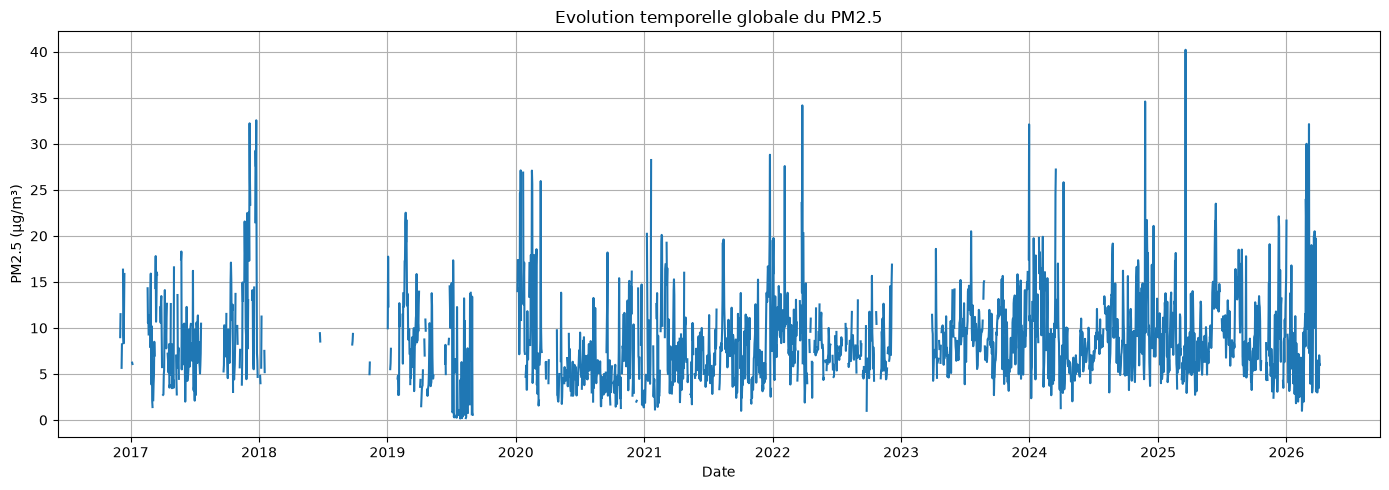


========== ACF / PACF ==========


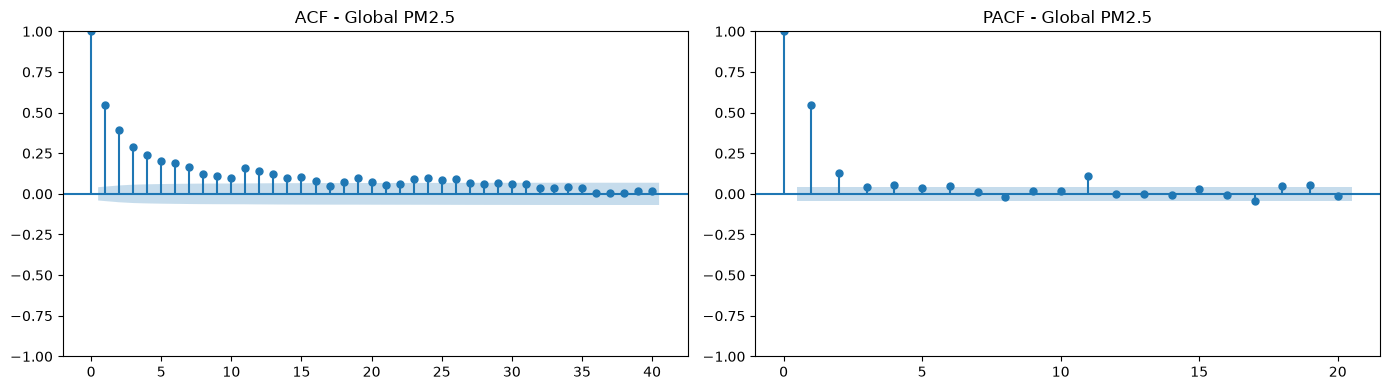


========== STATION-LEVEL TIME SERIES ANALYSIS ==========
Station ignorée (moins de 60 mesures) : Albors - Valencia
Station ignorée (moins de 60 mesures) : Avinguda Meridiana, Sagerra
Station ignorée (moins de 60 mesures) : Barcelona
Station ignorée (moins de 60 mesures) : Barcelona - Camp d'en Grassot
Station ignorée (moins de 60 mesures) : C. Restoy, 51, Almeria, Spain
Station ignorée (moins de 60 mesures) : Gibraltar
Station ignorée (moins de 60 mesures) : Martorell
Station ignorée (moins de 60 mesures) : Reus
Station ignorée (moins de 60 mesures) : Rosia Road
Station ignorée (moins de 60 mesures) : Sant Adrià de Besòs
Station ignorée (moins de 60 mesures) : Sant Francesc
Station ignorée (moins de 60 mesures) : Terrassa
Station ignorée (moins de 60 mesures) : Viladecavalls 
Fichier sauvegardé : c:\Users\WINDOWS\Desktop\PM2.5-Forecasting\results\G22\Exploratory_temporal.csv


,node_id,n_records,pct_missing_intervals,acf_lag1,acf_lag7,ljung_box_p,adf_p,kpss_p
0,AIX CENTRE ECOLE ART,458,42.535,0.606,0.105,0.000,0.000,0.100
1,AIX ROY RENE,198,42.274,0.680,0.275,0.000,0.001,0.039
2,ALBALAT DELS TARONGERS,798,63.158,0.579,0.173,0.000,0.000,0.010
3,ALCANTARILLA,268,34.314,0.306,0.166,0.000,0.000,0.100
4,ALCORA,761,63.882,0.078,0.018,0.003,0.000,0.010
...,...,...,...,...,...,...,...,...
73,VILA-SECA (IES VILA-SECA),442,40.591,0.476,0.058,0.000,0.000,0.100
74,VILAMARXANT,346,87.678,0.300,0.114,0.000,0.000,0.073
75,VILLENA PARQUE FERIA,498,33.065,0.423,0.106,0.000,0.000,0.100
76,Vila-seca,638,42.158,0.179,0.031,0.000,0.000,0.100



========== YEARLY PM2.5 ANALYSIS ==========


,mediane,iqr,pct_sup_25,pct_sup_50
date,,,,
2016,10.17,7.06,1.80,0.00
2017,7.67,7.30,3.83,0.33
2018,7.02,6.17,0.40,0.00
2019,6.72,9.39,4.29,0.06
2020,5.71,6.56,2.06,0.09
2021,6.80,7.43,2.38,0.59
2022,8.12,7.36,2.02,0.46
2023,9.00,7.43,2.44,0.20
2024,8.00,6.93,3.15,0.21


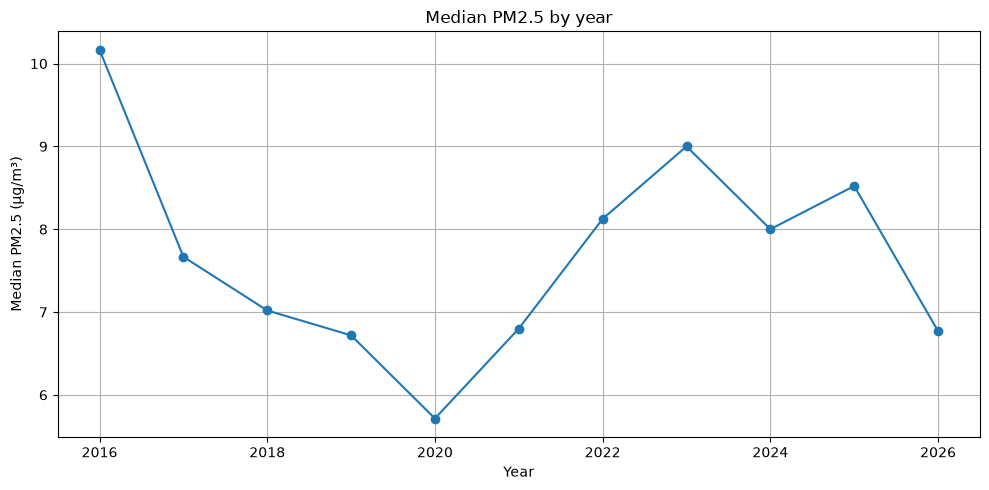


========== LEAD-LAG CORRELATIONS ==========
Lead-lag correlations :


,k=0,k=1,k=2,k=3
temperature_celsius,0.04,0.03,0.02,-0.01
pressure_mb,0.20,0.26,0.23,0.17
wind_u,-0.18,-0.20,-0.12,-0.07
wind_v,0.09,0.05,-0.01,-0.03
NO2,0.24,0.20,0.08,0.08
CO,0.06,0.07,0.06,0.04
O3,-0.16,-0.14,-0.13,-0.11
AOD,0.17,0.10,0.03,0.02



========== ARIMA DIAGNOSTICS ==========
ADF p-value  = 0.0000
KPSS p-value = 0.0116
Ordre de différenciation suggéré : d = 1
ACF lag 7 médiane = 0.105
Une forte autocorrélation au lag 7 peut indiquer une dépendance hebdomadaire à examiner.

TIME SERIES ANALYSIS TERMINEE !

Fichiers sauvegardés dans : c:\Users\WINDOWS\Desktop\PM2.5-Forecasting\results\G22
- .gitkeep
- data_features.csv
- Exploratory_Data.csv
- Exploratory_temporal.csv
- feature_config.json
- folds_spatial.json
- folds_standard.json
- folds_temporal.json
- global_pm25_daily_series.csv
- lead_lag_correlations.csv
- timeseries_diagnostics.json
- yearly_pm25_analysis.csv


In [1]:

# ============================================================
# PM2.5 FORECASTING - PART B: TIME SERIES ANALYSIS
# Adapted for VS Code
# ============================================================

# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import json
import warnings

from pathlib import Path
from IPython.display import display

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning

warnings.filterwarnings("ignore")
warnings.simplefilter("ignore", InterpolationWarning)

np.random.seed(42)

# ============================================================
# PROJECT CONFIGURATION
# ============================================================

CURRENT = Path.cwd()

ROOT = next(
    (p for p in [CURRENT, *CURRENT.parents] if (p / "data").is_dir()),
    CURRENT.parent if CURRENT.name == "notebooks" else CURRENT
)

DATA_PATH = ROOT / "data" / "raw" / "combined_gee_pm25.csv"

GROUPE = "G22"

OUT = ROOT / "results" / GROUPE
FIGURES = ROOT / "figures"

OUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

print("PROJECT ROOT:", ROOT)
print("DATASET PATH:", DATA_PATH)

# ============================================================
# ETAPE 1 : CHARGEMENT ET PREPARATION DES DONNEES
# ============================================================

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset introuvable : {DATA_PATH}\n"
        "Vérifie que le fichier est dans data/raw/"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset initial :", df.shape)

# Détection des colonnes
def trouver(mots):
    for c in df.columns:
        if any(m in c.lower() for m in mots):
            return c
    return None

DATE = trouver(["date", "time"])
TARGET = trouver(["pm2.5", "pm25", "pm2_5"])
STATION = "sensor_name"

if DATE is None or TARGET is None or STATION not in df.columns:
    raise ValueError(
        "Colonnes nécessaires introuvables.\n"
        f"Colonnes disponibles : {df.columns.tolist()}"
    )

print("Date :", DATE)
print("Station :", STATION)
print("Cible :", TARGET)

# Conversion des dates
df[DATE] = pd.to_datetime(
    df[DATE], errors="coerce"
).dt.normalize()

# Nettoyage de la cible
df = df[
    df[TARGET].notna()
    & (df[TARGET] > 0)
    & (df[TARGET] < 500)
    & df[DATE].notna()
].copy()

# Suppression des doublons
df = df.drop_duplicates()

# Une mesure moyenne par station et par jour
df = df.groupby(
    [STATION, DATE],
    as_index=False
).agg({
    c: "mean" if pd.api.types.is_numeric_dtype(df[c])
    else "first"
    for c in df.columns
    if c not in [STATION, DATE]
})

df = df.sort_values([STATION, DATE])

print("\nDataset après préparation :", df.shape)
print("Nombre de stations :", df[STATION].nunique())
print("Période :", df[DATE].min(), "->", df[DATE].max())

# ============================================================
# ETAPE 2 : ANALYSE TEMPORELLE GLOBALE
# ============================================================

print("\n========== GLOBAL TIME SERIES ANALYSIS ==========")

serie = (
    df.groupby(DATE)[TARGET]
    .median()
    .sort_index()
    .asfreq("D")
)

serie_clean = serie.dropna()

if len(serie_clean) < 5:
    raise ValueError("Pas assez de données temporelles.")

print("Nombre de jours observés :", len(serie_clean))
print("Premier jour :", serie_clean.index.min())
print("Dernier jour :", serie_clean.index.max())
print("Jours manquants dans la série :", serie.isna().sum())

# Evolution temporelle globale
plt.figure(figsize=(14, 5))

plt.plot(serie.index, serie.values)

plt.title("Evolution temporelle globale du PM2.5")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(True)

plt.tight_layout()
plt.savefig(
    FIGURES / "global_pm25_timeseries.png",
    bbox_inches="tight"
)
plt.show()

# ============================================================
# ETAPE 3 : AUTOCORRELATION ACF ET PACF
# ============================================================

print("\n========== ACF / PACF ==========")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(
    serie_clean,
    lags=min(40, len(serie_clean) // 2 - 1),
    ax=ax[0]
)

plot_pacf(
    serie_clean,
    lags=min(20, len(serie_clean) // 2 - 1),
    ax=ax[1],
    method="ywm"
)

ax[0].set_title("ACF - Global PM2.5")
ax[1].set_title("PACF - Global PM2.5")

plt.tight_layout()
plt.savefig(
    FIGURES / "global_acf_pacf.png",
    bbox_inches="tight"
)
plt.show()

# ============================================================
# ETAPE 4 : ANALYSE TEMPORELLE PAR STATION
# ============================================================

print("\n========== STATION-LEVEL TIME SERIES ANALYSIS ==========")

tempo = []

for st, g in df.groupby(STATION):

    s = (
        g.set_index(DATE)[TARGET]
        .sort_index()
    )

    full_dates = pd.date_range(
        s.index.min(),
        s.index.max(),
        freq="D"
    )

    s = s.reindex(full_dates)

    x = s.dropna()

    if len(x) < 60:
        print(f"Station ignorée (moins de 60 mesures) : {st}")
        continue

    # ACF
    a = acf(
        s.values,
        nlags=10,
        missing="conservative"
    )

    # Tendance
    pente = stats.linregress(
        (x.index - x.index[0]).days,
        x.values
    )

    # PACF
    try:
        pacf_lag1 = acf(x, nlags=2)[1]
    except Exception:
        pacf_lag1 = np.nan

    # Ljung-Box
    try:
        ljung_p = acorr_ljungbox(
            x,
            lags=[7]
        )["lb_pvalue"].iloc[0]
    except Exception:
        ljung_p = np.nan

    # ADF
    try:
        adf_p = adfuller(x)[1]
    except Exception:
        adf_p = np.nan

    # KPSS
    try:
        kpss_p = kpss(
            x,
            nlags="auto"
        )[1]
    except Exception:
        kpss_p = np.nan

    # Variation mensuelle
    seasonal = x.groupby(x.index.month).mean()

    # Drift entre première et deuxième moitié
    drift_p = stats.ks_2samp(
        x.iloc[:len(x) // 2],
        x.iloc[len(x) // 2:]
    ).pvalue

    tempo.append({
        "model_id": "arima_woa_lstm_pm25",
        "model_group": GROUPE,
        "variable": TARGET,
        "node_id": st,

        "n_records": len(x),

        "t_min": x.index.min().date(),
        "t_max": x.index.max().date(),

        "sampling_interval_median_sec":
            x.index.to_series()
            .diff()
            .dt.total_seconds()
            .median(),

        "pct_missing_intervals":
            100 * s.isna().mean(),

        "acf_lag1": a[1],
        "acf_lag7": a[7],

        "pacf_lag1": pacf_lag1,

        "ljung_box_p": ljung_p,

        "adf_p": adf_p,
        "kpss_p": kpss_p,

        "trend_slope_per_day": pente.slope,
        "trend_pval": pente.pvalue,

        "seasonal_amplitude":
            seasonal.max() - seasonal.min(),

        "target_drift_pval": drift_p,

        "n_days_above_25": (x > 25).sum(),
        "n_days_above_50": (x > 50).sum(),

        "pct_days_above_25":
            100 * (x > 25).mean(),

        "pct_days_above_50":
            100 * (x > 50).mean(),

        "cv_strategy_recommended": "temporal",

        "gap_between_train_test_sec": 86400
    })

tempo = pd.DataFrame(tempo)

tempo.to_csv(
    OUT / "Exploratory_temporal.csv",
    index=False
)

print("Fichier sauvegardé :", OUT / "Exploratory_temporal.csv")

if not tempo.empty:

    display(
        tempo[
            [
                "node_id",
                "n_records",
                "pct_missing_intervals",
                "acf_lag1",
                "acf_lag7",
                "ljung_box_p",
                "adf_p",
                "kpss_p"
            ]
        ].round(3)
    )

else:
    print("Aucune station avec suffisamment de données.")

# ============================================================
# ETAPE 5 : EVOLUTION ANNUELLE DU PM2.5
# ============================================================

print("\n========== YEARLY PM2.5 ANALYSIS ==========")

derive = df.groupby(
    df[DATE].dt.year
)[TARGET].agg(
    mediane="median",
    iqr=lambda s: s.quantile(.75) - s.quantile(.25),
    pct_sup_25=lambda s: 100 * (s > 25).mean(),
    pct_sup_50=lambda s: 100 * (s > 50).mean()
)

display(derive.round(2))

derive.to_csv(
    OUT / "yearly_pm25_analysis.csv"
)

# Graphique annuel
plt.figure(figsize=(10, 5))

derive["mediane"].plot(marker="o")

plt.title("Median PM2.5 by year")
plt.xlabel("Year")
plt.ylabel("Median PM2.5 (µg/m³)")
plt.grid(True)

plt.tight_layout()
plt.savefig(
    FIGURES / "yearly_pm25.png",
    bbox_inches="tight"
)
plt.show()

# ============================================================
# ETAPE 6 : LEAD-LAG CORRELATIONS
# ============================================================

print("\n========== LEAD-LAG CORRELATIONS ==========")

CLES = [TARGET] + [
    c for c in df.select_dtypes("number").columns
    if c != TARGET
    and any(m in c.lower() for m in [
        "aod", "no2", "co", "o3", "temp",
        "press", "wind", "u_", "v_"
    ])
][:8]

ll = {
    c: [
        df.groupby(STATION).apply(
            lambda g: g[TARGET].corr(
                g[c].shift(k)
            )
        ).median()

        for k in range(4)
    ]

    for c in CLES[1:]
}

print("Lead-lag correlations :")

display(
    pd.DataFrame(
        ll,
        index=["k=0", "k=1", "k=2", "k=3"]
    ).T.round(2)
)

# Sauvegarde
pd.DataFrame(
    ll,
    index=["k=0", "k=1", "k=2", "k=3"]
).T.to_csv(
    OUT / "lead_lag_correlations.csv"
)

# ============================================================
# ETAPE 7 : ARIMA DIAGNOSTICS
# ============================================================

print("\n========== ARIMA DIAGNOSTICS ==========")

p_adf = adfuller(serie_clean)[1]

p_kpss = kpss(
    serie_clean,
    nlags="auto"
)[1]

d = 0 if (
    p_adf < 0.05 and p_kpss > 0.05
) else 1

print(f"ADF p-value  = {p_adf:.4f}")
print(f"KPSS p-value = {p_kpss:.4f}")

print(
    f"Ordre de différenciation suggéré : d = {d}"
)

acf_lag7_median = (
    tempo["acf_lag7"].median()
    if not tempo.empty else np.nan
)

print(
    f"ACF lag 7 médiane = {acf_lag7_median:.3f}"
)

print(
    "Une forte autocorrélation au lag 7 peut indiquer "
    "une dépendance hebdomadaire à examiner."
)

# ============================================================
# ETAPE 8 : SAUVEGARDE DES RESULTATS
# ============================================================

diagnostics = {
    "model_id": "arima_woa_lstm_pm25",
    "model_group": GROUPE,
    "target": TARGET,

    "global_adf_p": float(p_adf),
    "global_kpss_p": float(p_kpss),

    "suggested_d": int(d),

    "median_acf_lag7": (
        float(acf_lag7_median)
        if pd.notna(acf_lag7_median)
        else None
    ),

    "n_stations_analyzed": len(tempo)
}

with open(
    OUT / "timeseries_diagnostics.json",
    "w"
) as f:
    json.dump(diagnostics, f, indent=2)

# Sauvegarder la série temporelle globale
serie.to_csv(
    OUT / "global_pm25_daily_series.csv",
    header=["PM25"]
)

print("\n==========================================")
print("TIME SERIES ANALYSIS TERMINEE !")
print("==========================================")

print("\nFichiers sauvegardés dans :", OUT)

for file in OUT.iterdir():
    print("-", file.name)
